# CM laser: static and space-charge distortion corrections with PHGarfield

**Data**: CM laser clusters (LaserPadAggregator + LaserAggregatedClusterizer) of
- beam runs 79508, 79513, 79516, 79529 (I_GEM ~3-4 uA) and 80892, 81558 (~10 uA), 100-segment blocks 0 / 1000 / 2000 (17 blocks);
- no-beam field-on runs 75073 (before the IFC voltage change) and 83319 (after);
- no-beam field-off run 78242.

**Method**: every cluster is drift-corrected with PHGarfield (reverse drift through E and B; static part: field cage, module frames,
E x B with the TPC placement; space charge: 3D IBF map alpha1.6 x keff) and compared
- to the CM truth pattern (matcher),
- cluster to cluster to another run (beam - no beam, field on - field off), which cancels the truth pattern and whatever is common.

**Scan** (4905 jobs + 684 for the z extension): TPC tilt (rot_x, rot_y), TPC z shift, IFC voltages, module-frame charge, CM field,
keff 0.8-1.2 x CDB, alpha 1.6 / 2.0; reduced to ring profiles, harmonics and straight-track sagittas.

**Final configuration**: z -30 mm, tilt rot_x 0.16 / rot_y 0.85 mrad (survey x / y), IFC automatic (South +211 V after the change),
frame -180, 380 V/cm, alpha 1.6, keff fitted per block and side.

Conventions: residual = target - reference; R dphi and dR in mm; R rings of 3.75 cm (33-71 cm covered by the CM stripes;
dotted lines = readout module ring boundaries R1 / R2 / R3); sagitta = quadratic term of R dphi(R) over 30-76 cm
(100 um = 0.009 / GeV in q / pT at 1.4 T). Detailed backup for every section: `pdf/<section>.pdf`.

In [1]:
%matplotlib inline
import numpy as np, matplotlib.pyplot as plt
import cmplots as c
plt.rcParams['figure.dpi'] = 80
K = c.fitted_keff()          # keff (x CDB) per (run, block, side), beam - no beam
pdfs = {}
def show(figs):
    for f in figs:
        display(f)
    plt.close('all')

## a) Space charge: beam vs no beam, field on
Beam - no beam (75073), both with the field on, cluster to cluster: the static distortions are common and cancel at first order,
what is left is the space charge. Grey: no correction; blue: static correction only; red: static + space charge (alpha1.6, fitted keff).
The space-charge correction takes the beam - no beam difference from -2.7 / -1.5 mm (median, South / North) with a
1.3-1.7 mm spread to 0 +- 0.1 mm with a spread equal to the local cluster scatter.

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/cmplots.py:407: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, axs = plt.subplots(2, 3, figsize=(17, 8))


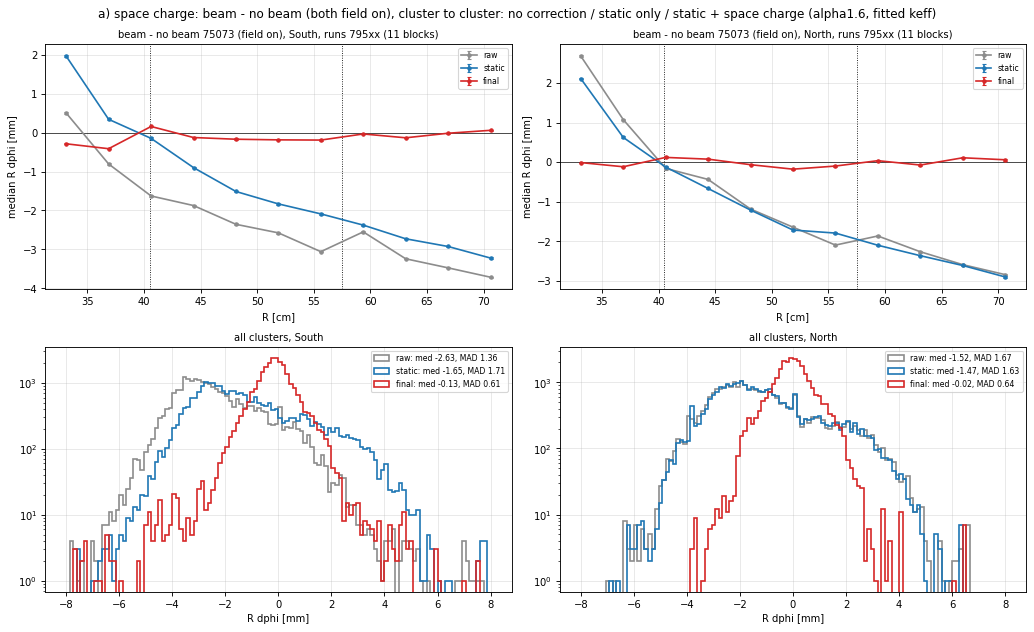

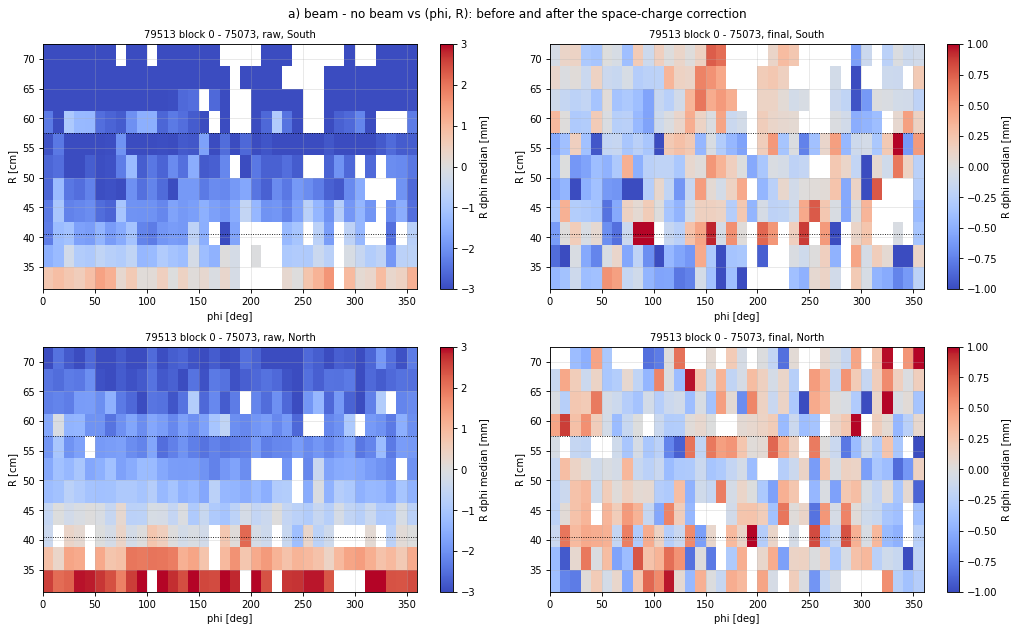

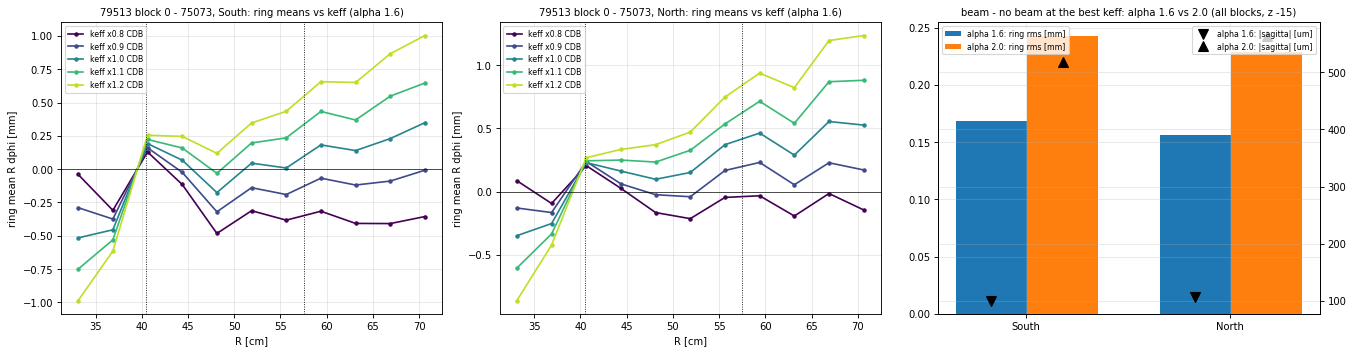

In [2]:
ma, ea = c.sec_a(); show(ma); pdfs['a'] = c.save_pdf('a_space_charge_beam_vs_nobeam', ma + ea)

## b) TPC tilt
The tilt of the TPC w.r.t. the magnetic field produces a first harmonic (dx, dy) of the residual.
Four independent measurements: no beam field on - field off (83319, 75073), beam - field off, and the North - South antisymmetric
part of beam vs truth (the truth pattern itself is common to both sides).

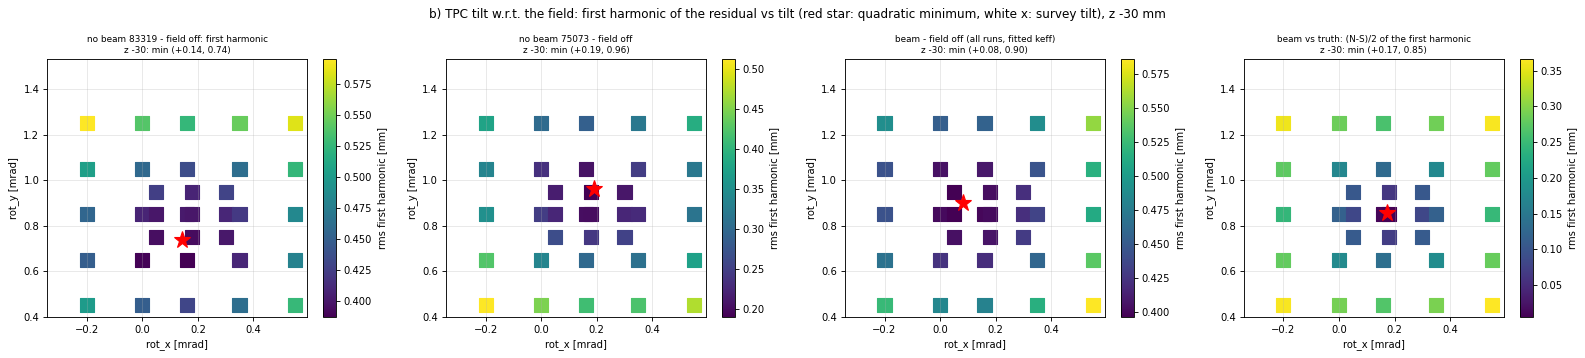

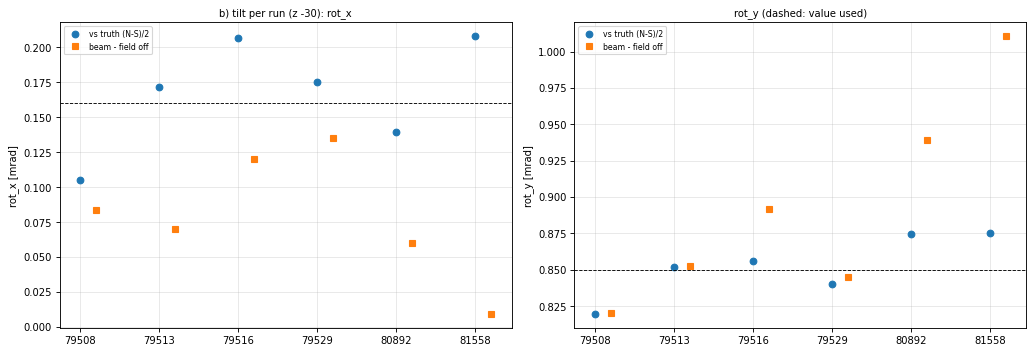

z -30 nb83319 : rot_x +0.14  rot_y 0.74 mrad
z -30 nb75073 : rot_x +0.19  rot_y 0.96 mrad
z -30 off     : rot_x +0.08  rot_y 0.90 mrad
z -30 truth   : rot_x +0.17  rot_y 0.85 mrad
z -15 nb83319 : rot_x +0.08  rot_y 0.82 mrad
z -15 nb75073 : rot_x +0.14  rot_y 0.93 mrad
z -15 off     : rot_x +0.07  rot_y 0.85 mrad
z -15 truth   : rot_x +0.18  rot_y 0.85 mrad


In [3]:
mb, eb, tilt = c.sec_b(K); show(mb); pdfs['b'] = c.save_pdf('b_tilt', mb + eb)
for k, v in tilt.items(): print(f"z {k[0]:+.0f} {k[1]:8s}: rot_x {v[0]:+.2f}  rot_y {v[1]:.2f} mrad")

## c) TPC z shift
A z shift changes where the drift starts in the magnetic field (Br at the ends): mostly the North sagitta.
Measured with no beam field on - field off and beam - field off (straight tracks: sagitta), and the North - South balance.

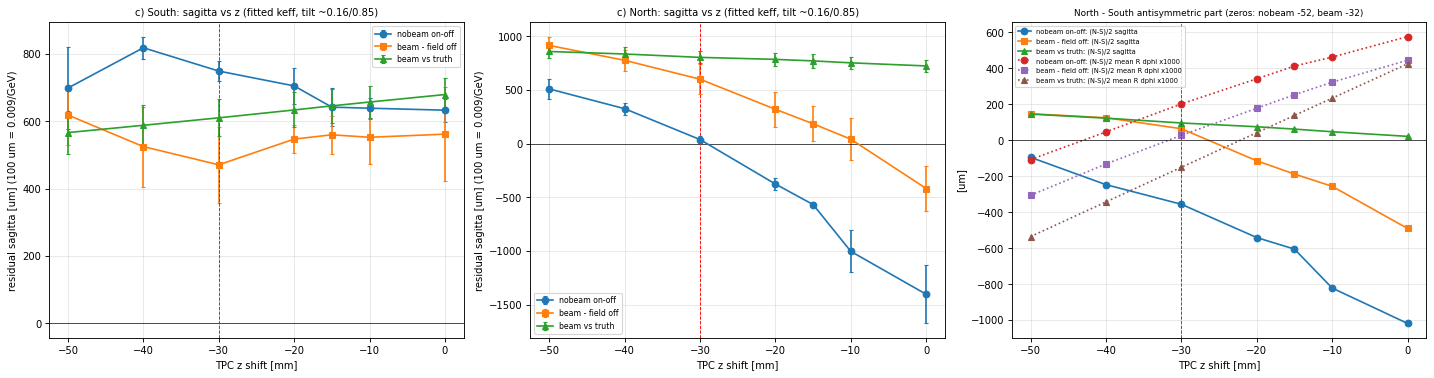

nobeam on-off     : (N-S)/2 sagitta = 0 at z -52.5 mm  (slope -18.2 um/mm)
beam - field off  : (N-S)/2 sagitta = 0 at z -31.5 mm  (slope -12.8 um/mm)


In [4]:
mc, ec, zest = c.sec_c(K); show(mc); pdfs['c'] = c.save_pdf('c_z_shift', mc + ec)
for z0, a, n in zest: print(f"{n:18s}: (N-S)/2 sagitta = 0 at z {z0:+.1f} mm  (slope {a:+.1f} um/mm)")

## d) IFC voltage (and the other static knobs)
- 79513 vs truth for IFC South 0-400 V and North -100..+100 V (z -15): the response is linear, falling with R.
- 83319 (after the IFC change) - 75073 (before), no beam: the South difference has the IFC shape and is removed by the
  static correction with 0 V vs 211 V; the North difference is a flat -1.2 mm (not IFC; North changed after the beam runs).
- At the final geometry: IFC +-60 V, module-frame charge, CM field, in no beam on - off, beam vs truth and beam - field off.

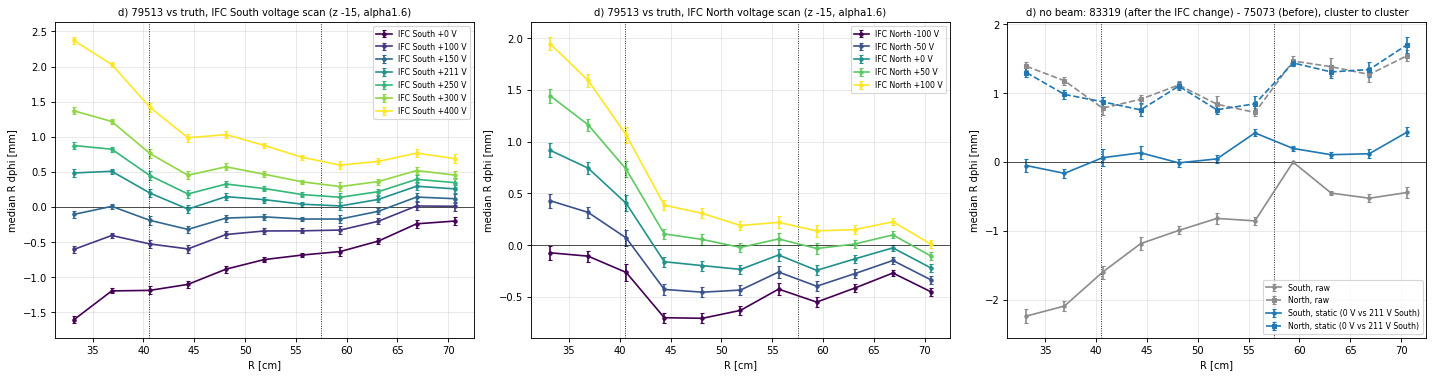

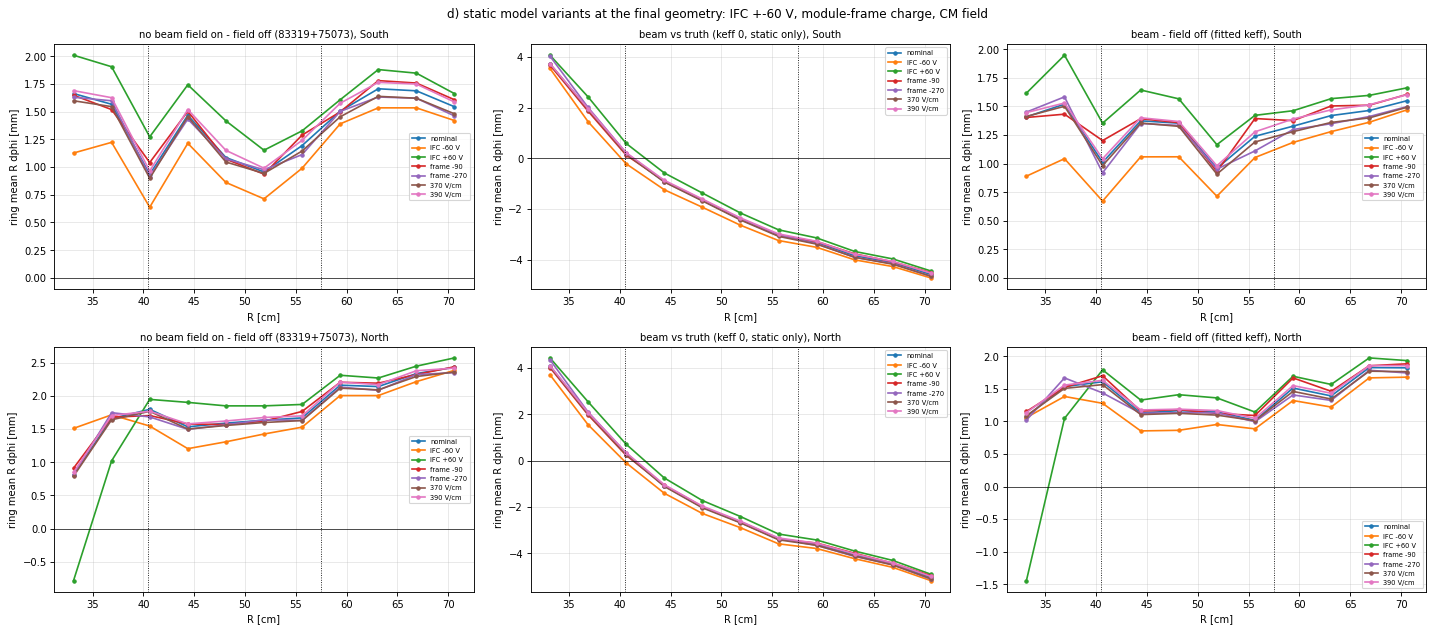

In [5]:
md_, ed_ = c.sec_d(K); show(md_); pdfs['d'] = c.save_pdf('d_ifc_static_model', md_ + ed_)

## e) keff
keff from beam - no beam (static part cancels): the keff that makes the profile flat in R and the one that makes tracks straight
(zero sagitta) agree; independent of the TPC geometry. Last plot: keff per 30 deg sector and module ring relative to the block keff
(the IBF map shape vs the data: stable between blocks and runs, same with both no-beam references).

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/cmplots.py:704: RuntimeWarning: Mean of empty slice
  m, sd = np.nanmean(G, 0), np.nanstd(G, 0)
/home/yoren/.local/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


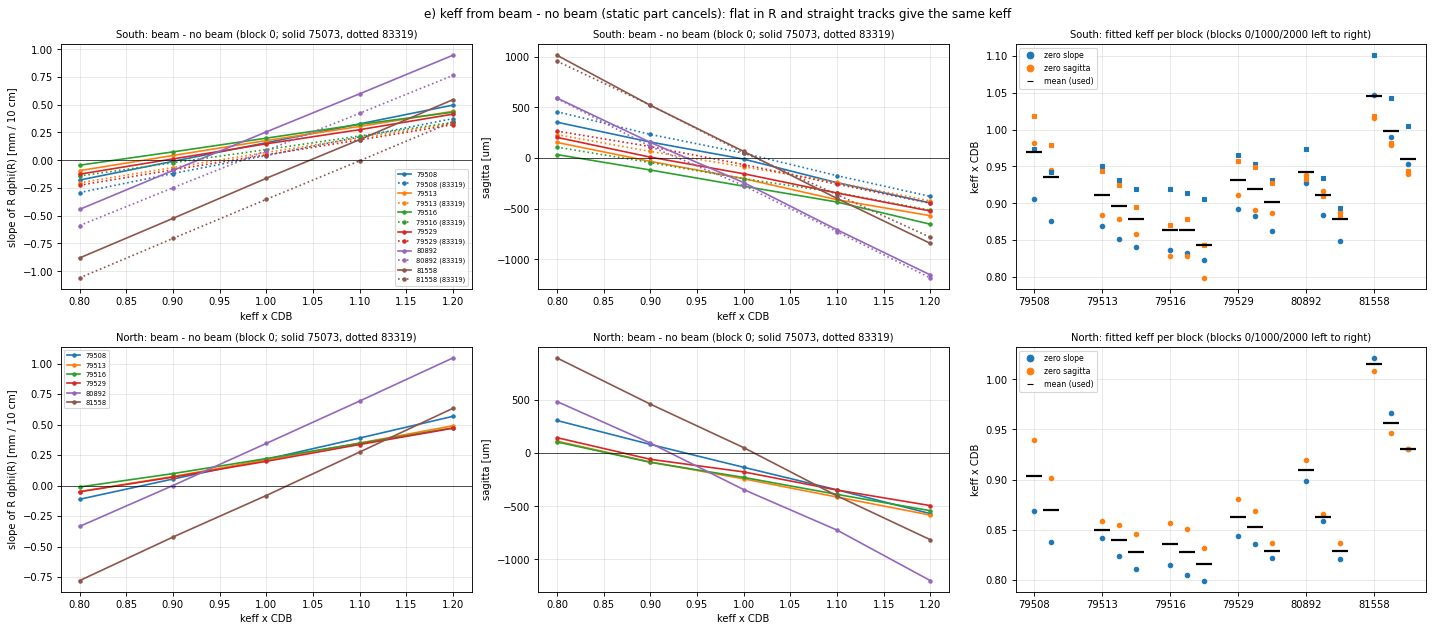

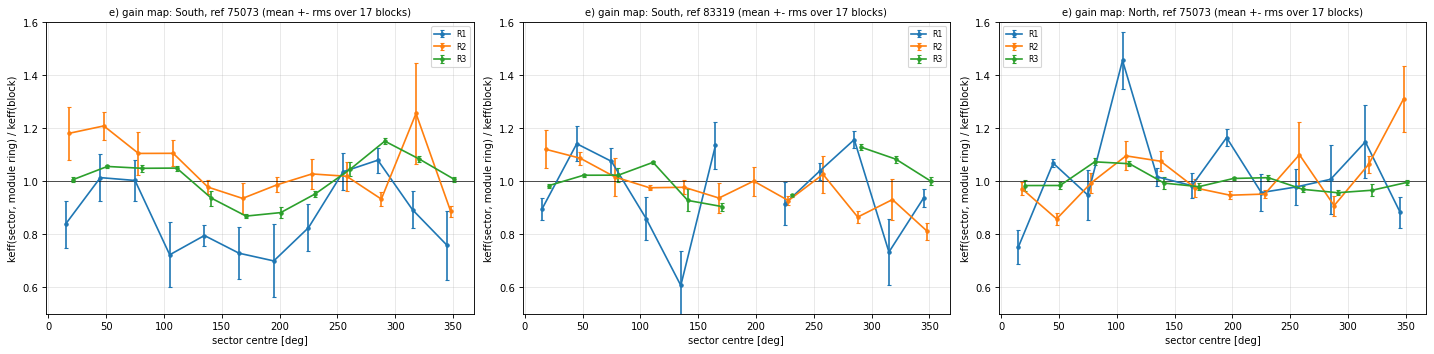

fitted keff (x CDB)  South / North
79508 blk 0: 0.970 / 0.904  blk 1000: 0.935 / 0.869
79513 blk 0: 0.912 / 0.850  blk 1000: 0.897 / 0.839  blk 2000: 0.878 / 0.828
79516 blk 0: 0.864 / 0.836  blk 1000: 0.863 / 0.828  blk 2000: 0.843 / 0.815
79529 blk 0: 0.931 / 0.862  blk 1000: 0.919 / 0.852  blk 2000: 0.902 / 0.829
80892 blk 0: 0.943 / 0.909  blk 1000: 0.911 / 0.862  blk 2000: 0.878 / 0.829
81558 blk 0: 1.045 / 1.015  blk 1000: 0.998 / 0.956  blk 2000: 0.960 / 0.930


In [6]:
me, ee = c.sec_e(K); show(me); pdfs['e'] = c.save_pdf('e_keff', me + ee)
import collections
print("fitted keff (x CDB)  South / North")
for run in c.BEAM:
    print(run, "  ".join(f"blk {b}: {K.get((run,b,0),np.nan):.3f} / {K.get((run,b,1),np.nan):.3f}" for b in (0,1000,2000) if (run,b,0) in K))

## f) Residual biases after the full correction
Main reference: field off (78242, no E x B) - matched robustly (radial offset per ring removed before matching).
Also shown: vs truth, field off vs truth, no beam - field off, beam - no beam. Constant R dphi is absorbed by the track fit;
what matters is the R shape (sagitta) and its phi dependence.

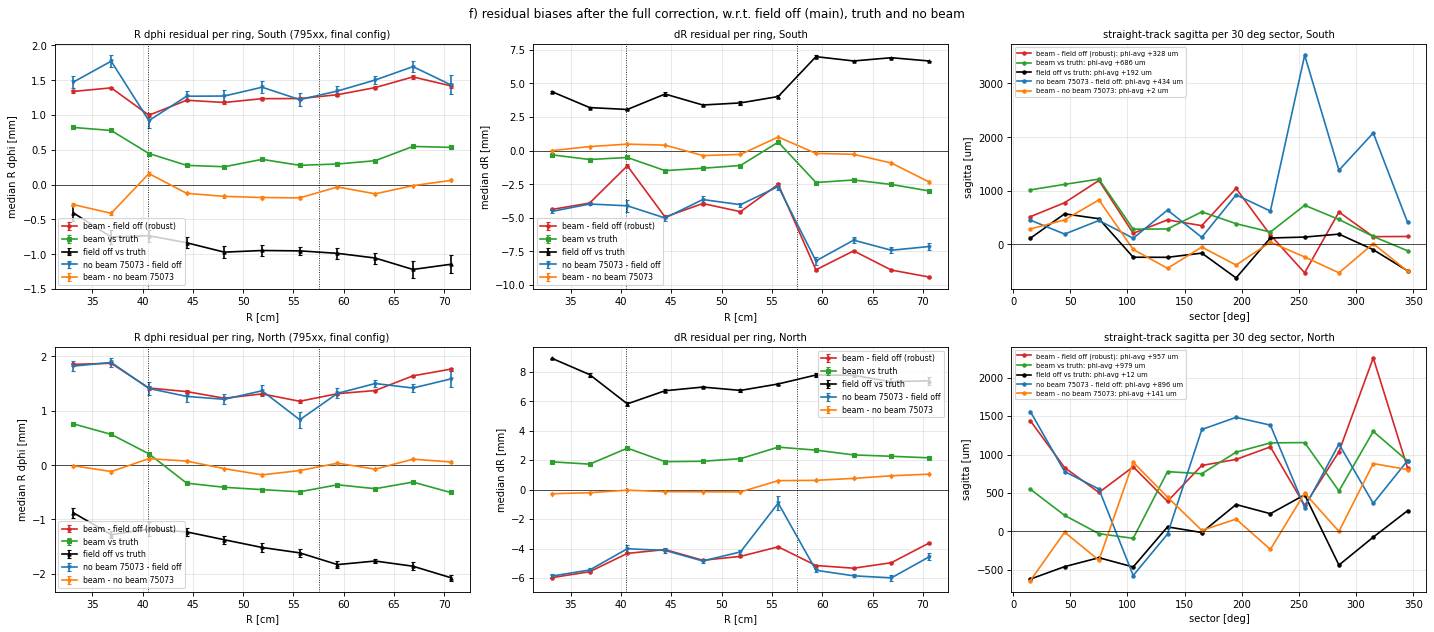

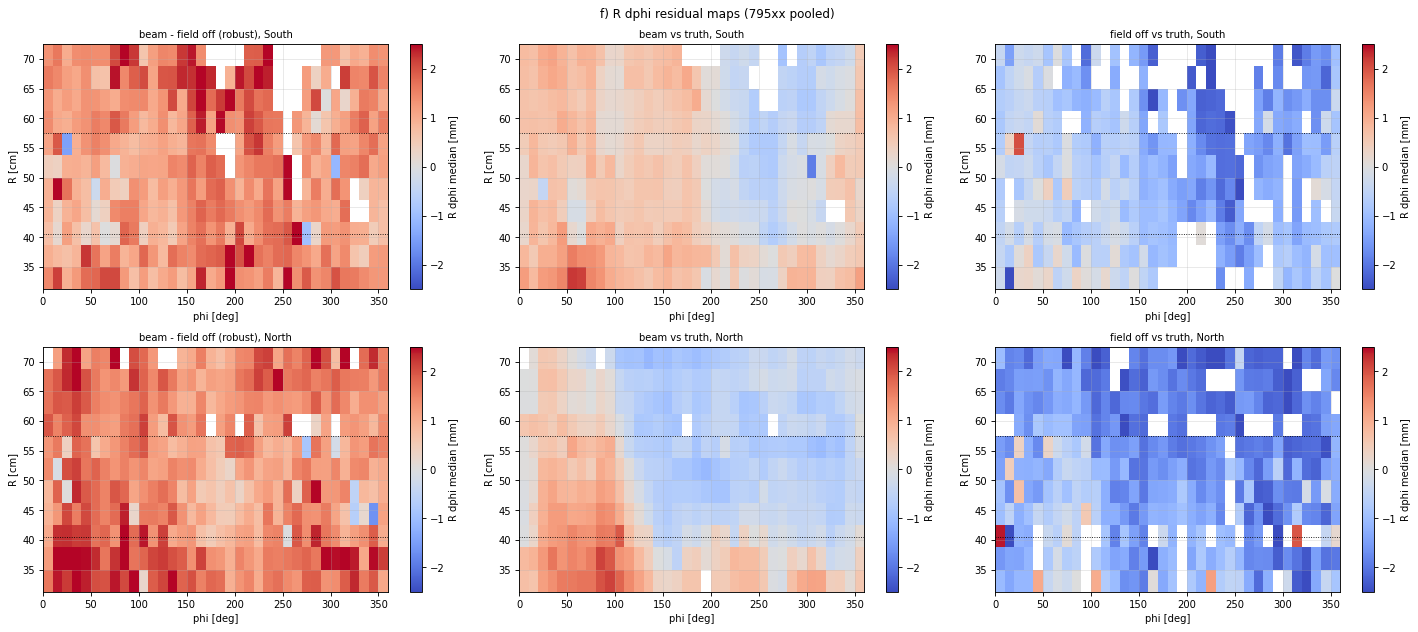

In [7]:
mf, ef = c.sec_f(); show(mf); pdfs['f'] = c.save_pdf('f_residual_biases', mf + ef)

## g) Resolution, step by step
Total width = spread of all residuals (includes the phi / R structure of the distortion); local width = residual minus the
leave-one-out median of its 10 deg x 3.75 cm cell (what is left after the structure: the resolution). Double Gaussian fits per ring
in the pdf.

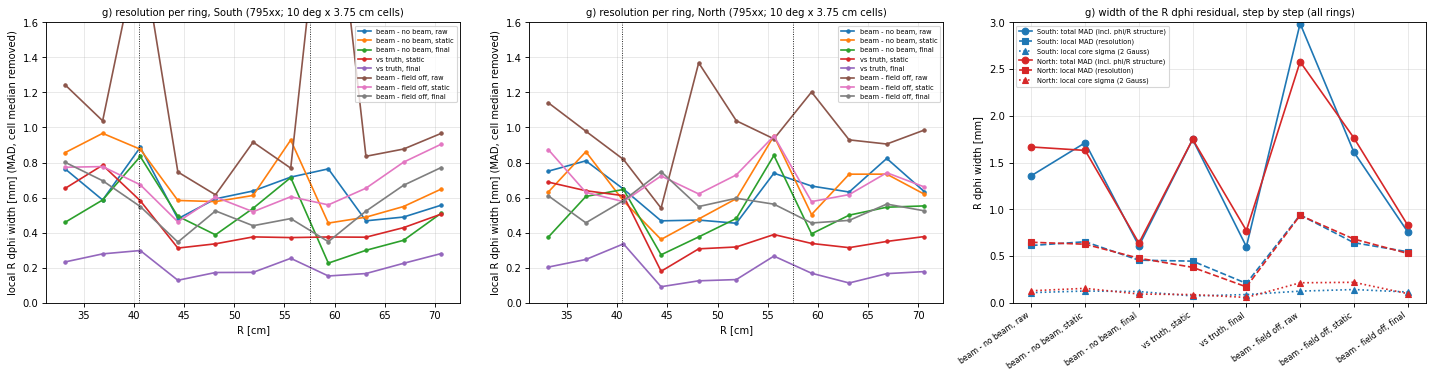

step                         South: total  local  core(frac) tail     North: total  local  core(frac) tail
beam - no beam, raw            1.36  0.61  0.11(13%) 0.70        1.67  0.65  0.13(14%) 0.78     
beam - no beam, static         1.71  0.65  0.13(13%) 0.75        1.63  0.63  0.15(18%) 0.81     
beam - no beam, final          0.61  0.46  0.12(24%) 0.63        0.64  0.48  0.09(22%) 0.66     
vs truth, static               1.75  0.45  0.07(11%) 0.51        1.75  0.38  0.09(17%) 0.48     
vs truth, final                0.60  0.21  0.09(34%) 0.30        0.77  0.17  0.06(27%) 0.22     
beam - field off, raw          2.99  0.94  0.12(9%) 0.92        2.58  0.93  0.21(13%) 1.00     
beam - field off, static       1.61  0.64  0.14(18%) 0.76        1.76  0.68  0.22(24%) 0.92     
beam - field off, final        0.76  0.55  0.12(21%) 0.64        0.83  0.53  0.10(20%) 0.60     


In [8]:
mg, eg, tab = c.sec_g(); show(mg[:1]); pdfs['g'] = c.save_pdf('g_resolution', mg + eg)
print(f"{'step':28s} {'South: total  local  core(frac) tail':40s} {'North: total  local  core(frac) tail'}")
for lab in dict.fromkeys(k[0] for k in tab):
    row = f"{lab:28s}"
    for s in (0, 1):
        t = tab[(lab, s)]; f = t['fit'] or {}
        g2 = f.get('g2')
        row += f"  {t['total']:5.2f} {t['local']:5.2f}  " + (f"{g2[2]:.2f}({100*f['core_frac']:.0f}%) {g2[4]:.2f}" if g2 is not None else "   -          ") + "     "
    print(row)

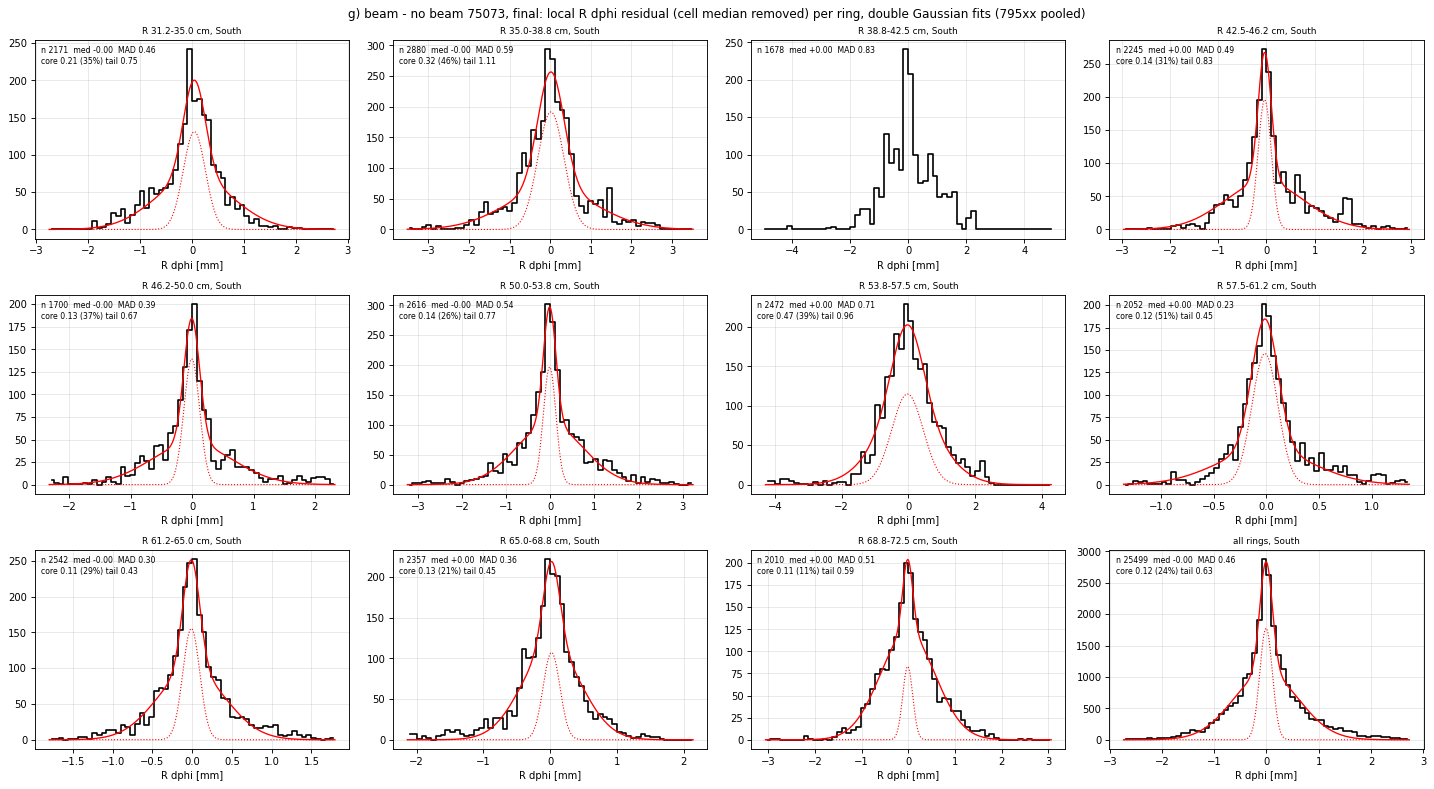

In [9]:
show(mg[1:])

Same per-ring histograms for **dR** (q=3) and for the residual itself instead of the local residual (local=False);
any comparison / stage: `c.ring_hists(cmpn, stage, q, blks=None, local=True)` with cmpn in NB75, NB83, OFF, T and stage raw / static / final.

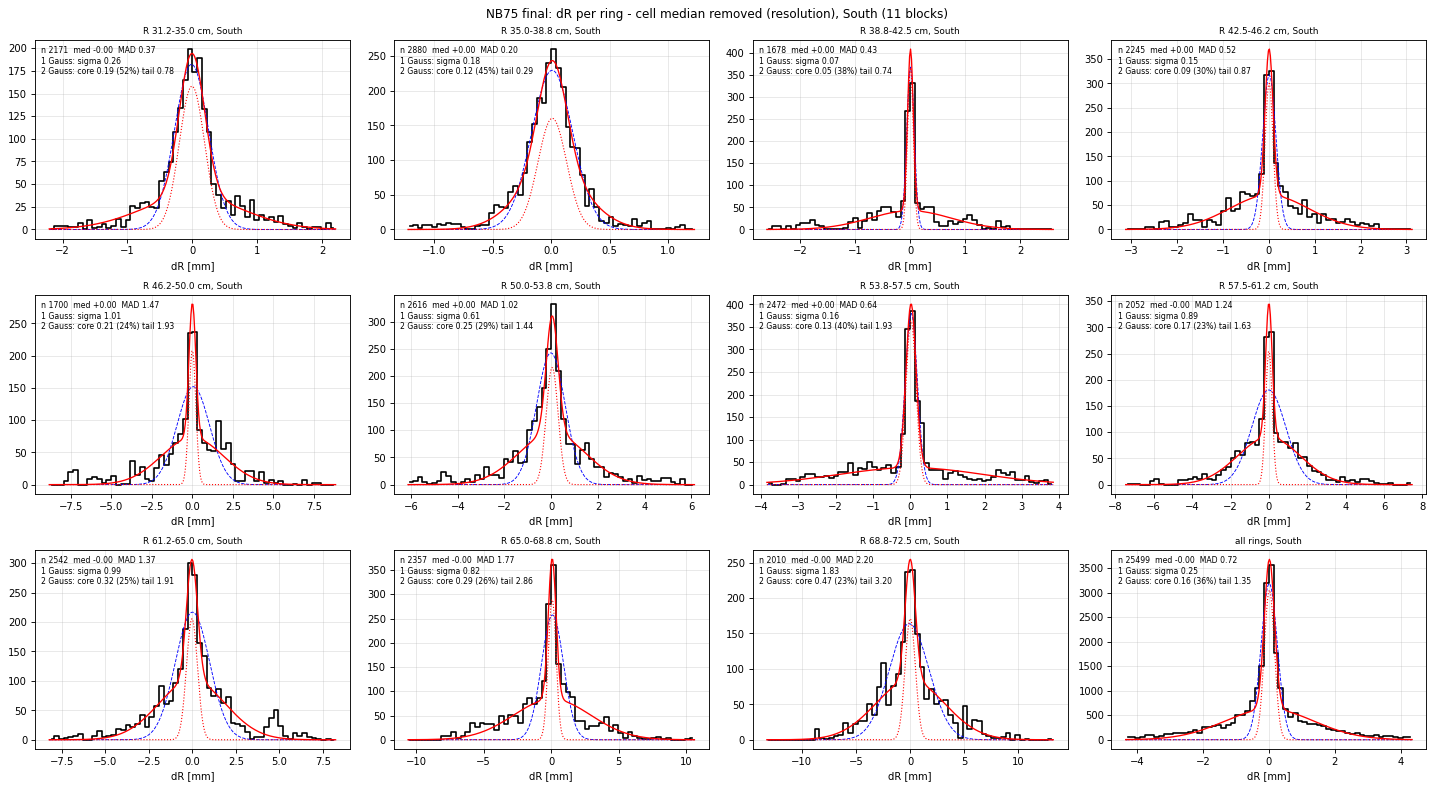

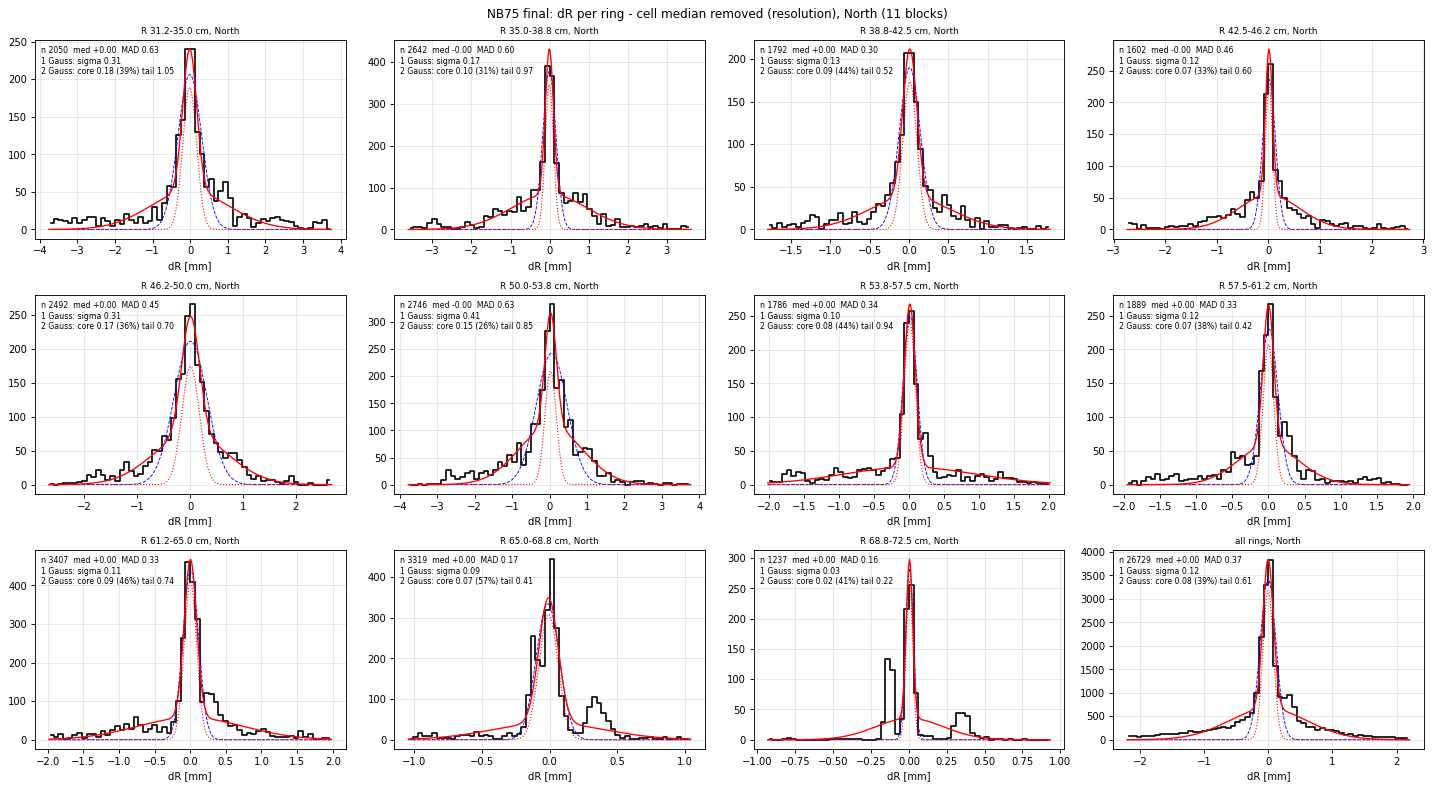

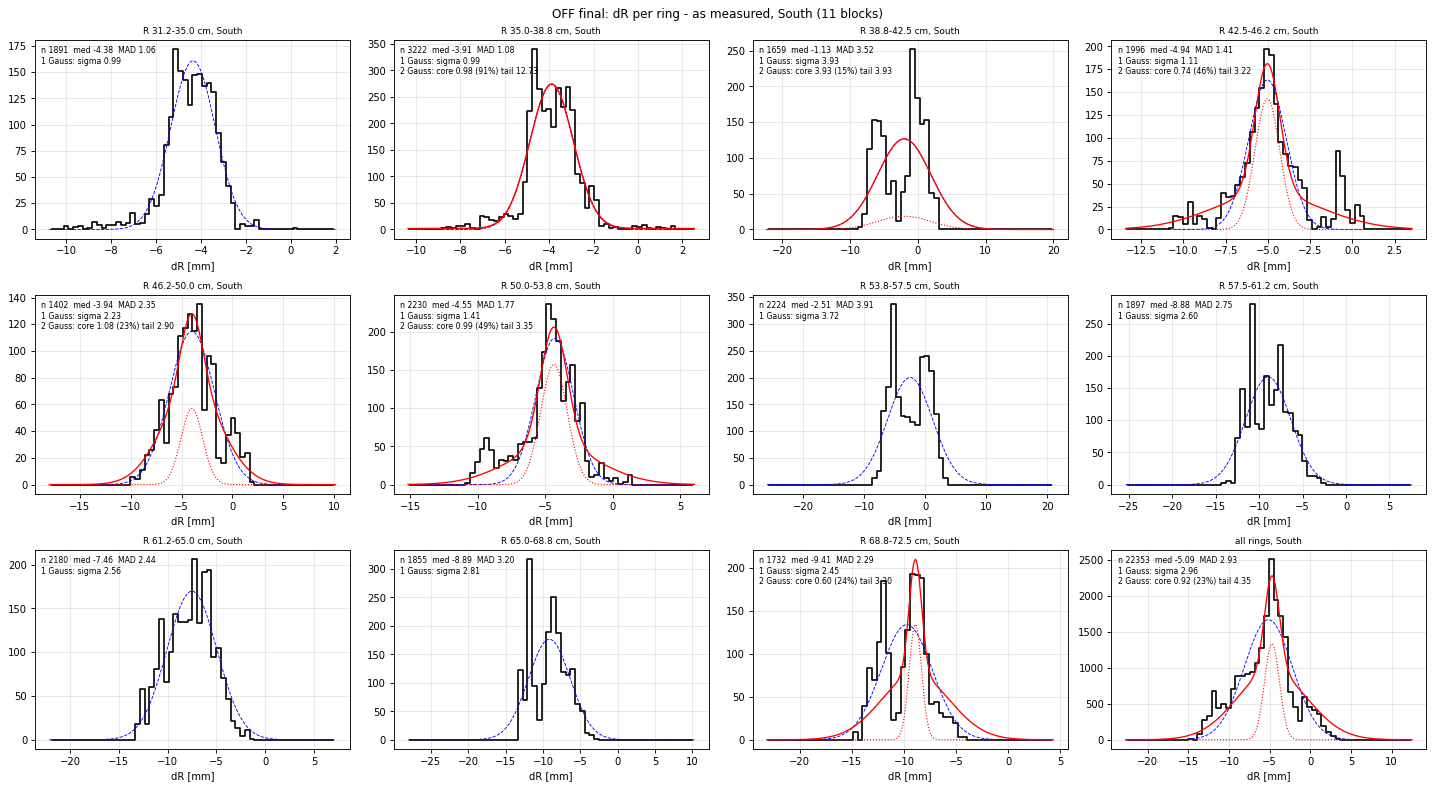

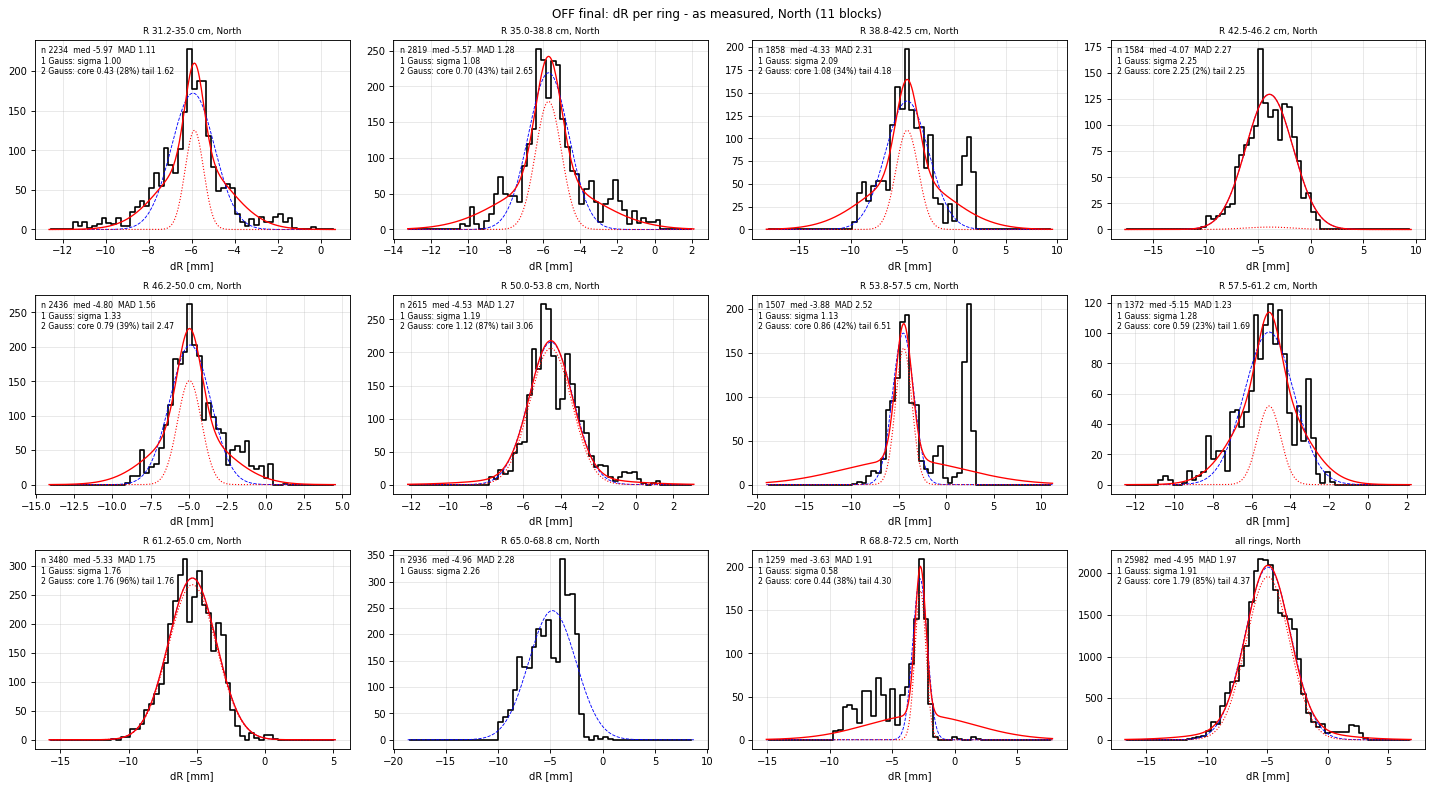

In [10]:
show(c.ring_hists('NB75', 'final', q=3))                 # local dR, beam - no beam
show(c.ring_hists('OFF', 'final', q=3, local=False))     # dR itself, beam - field off

### What a high-pT track sees
A track fit absorbs a straight line in R dphi(R) (offset + rotation). Per 10 deg phi bin (one track direction) a robust straight
line is fitted to the residuals and subtracted (`mode='line_phi'`): what is left contains the biases w.r.t. a straight line
(sagitta, module steps) plus the resolution. Compared with: as measured (`'none'`), one straight line per side (`'line_global'`),
and the local resolution (`'local'`). Width per ring for the four, then the line-subtracted histograms per ring
(the per-ring medians show the bias that the track keeps).

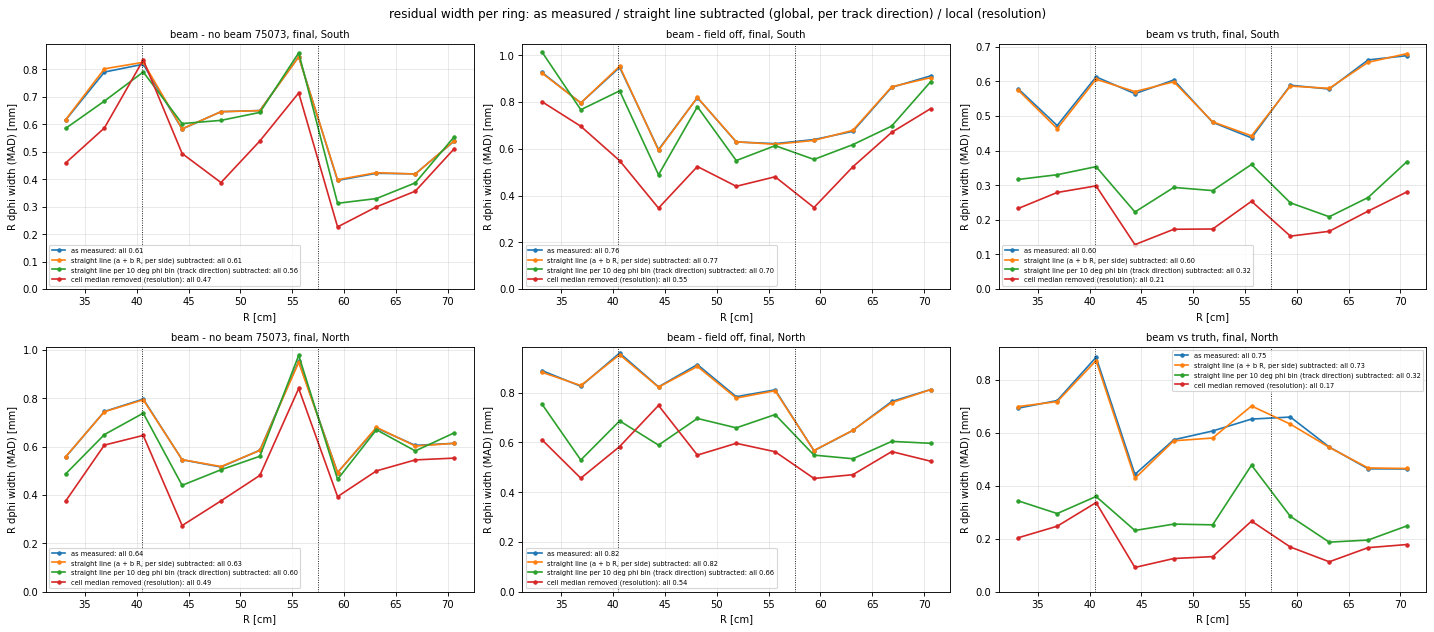

beam - no beam 75073   South as measured                                                    0.61 mm
beam - no beam 75073   South straight line (a + b R, per side) subtracted                   0.61 mm
beam - no beam 75073   South straight line per 10 deg phi bin (track direction) subtracted  0.56 mm
beam - no beam 75073   South cell median removed (resolution)                               0.47 mm
beam - no beam 75073   North as measured                                                    0.64 mm
beam - no beam 75073   North straight line (a + b R, per side) subtracted                   0.63 mm
beam - no beam 75073   North straight line per 10 deg phi bin (track direction) subtracted  0.60 mm
beam - no beam 75073   North cell median removed (resolution)                               0.49 mm
beam - field off       South as measured                                                    0.76 mm
beam - field off       South straight line (a + b R, per side) subtracted                   0.77 mm


In [11]:
fw, wrows = c.mode_widths(); show([fw])
for r in wrows: print(f"{r[0]:22s} {r[1]:5s} {c.MODE_TXT[r[2]]:62s} {r[3]:.2f} mm")

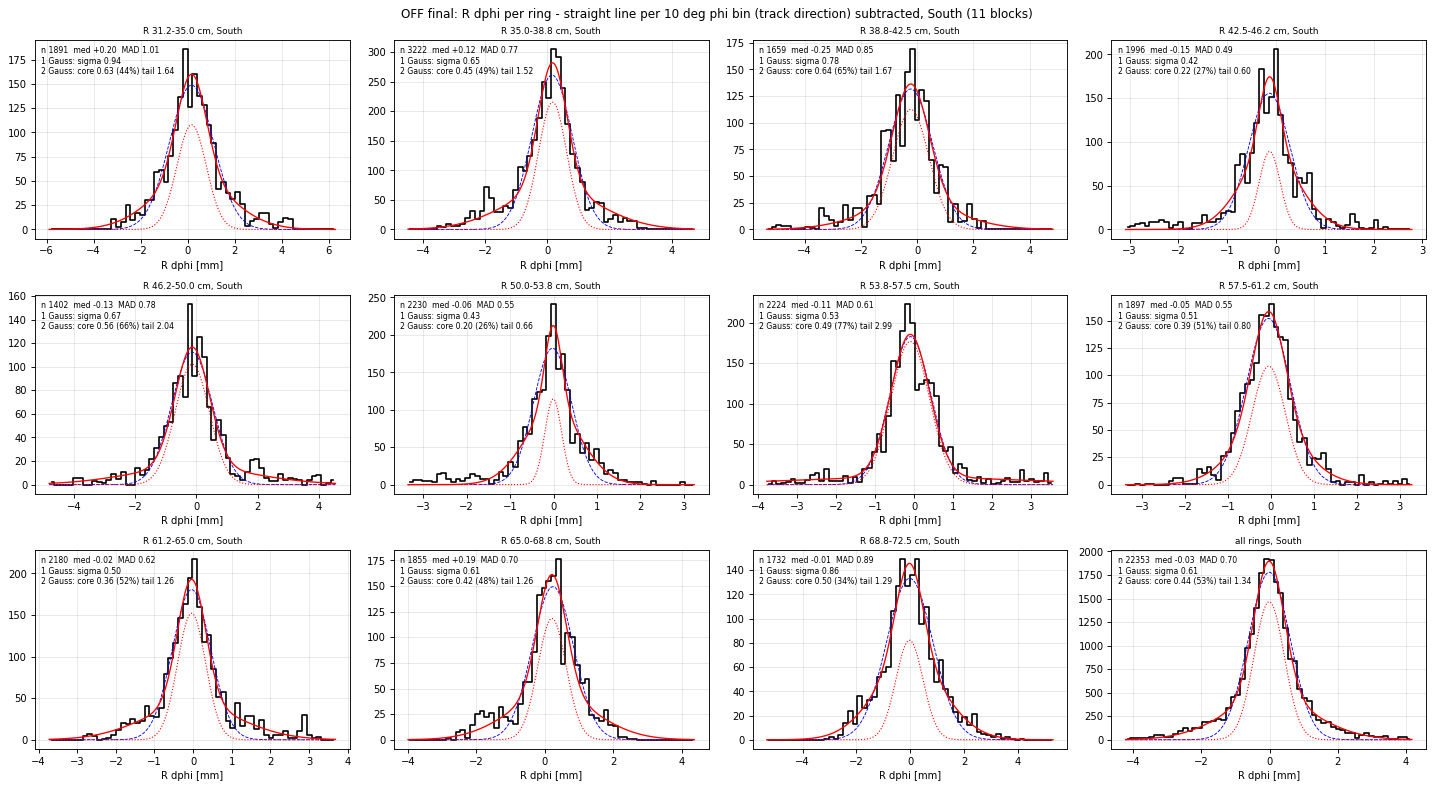

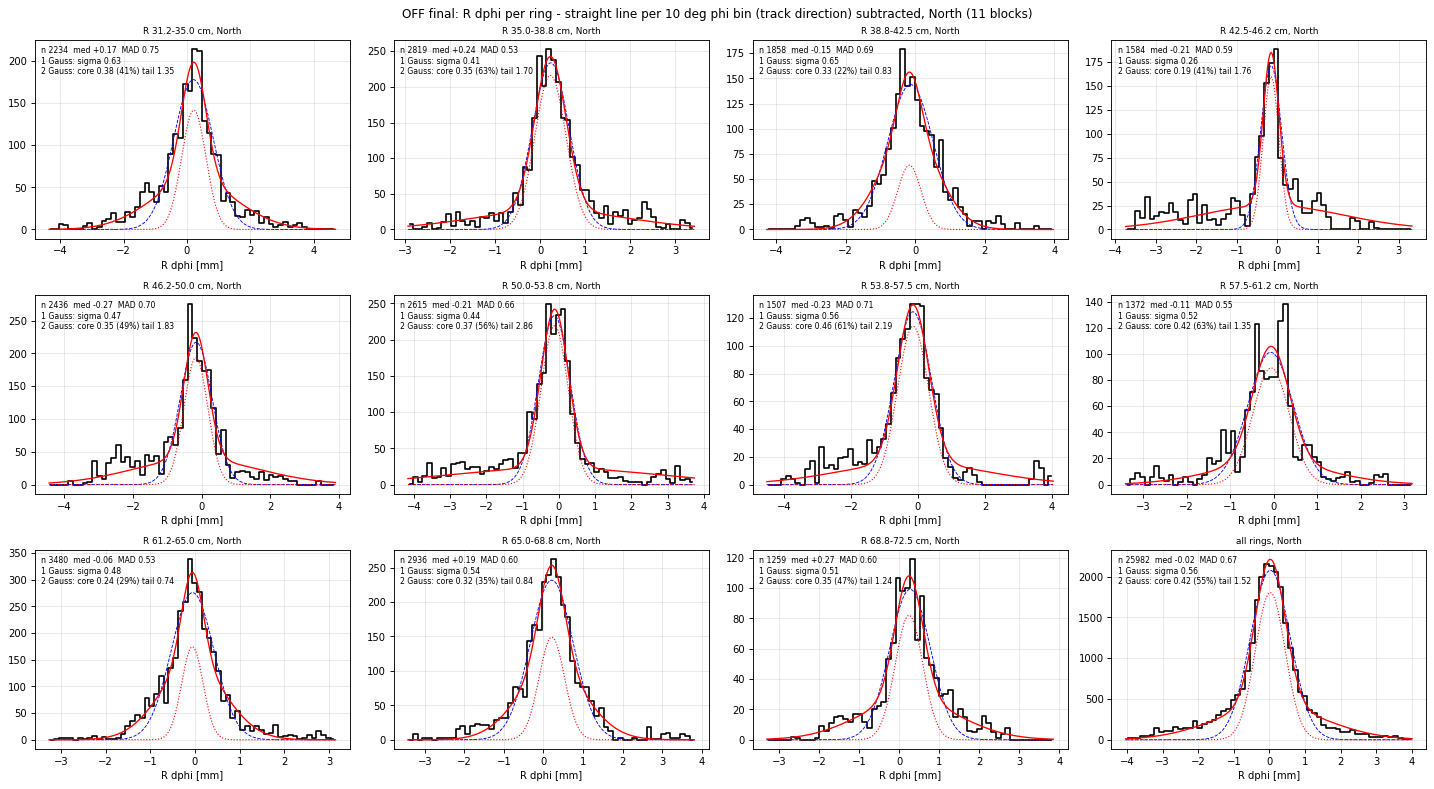

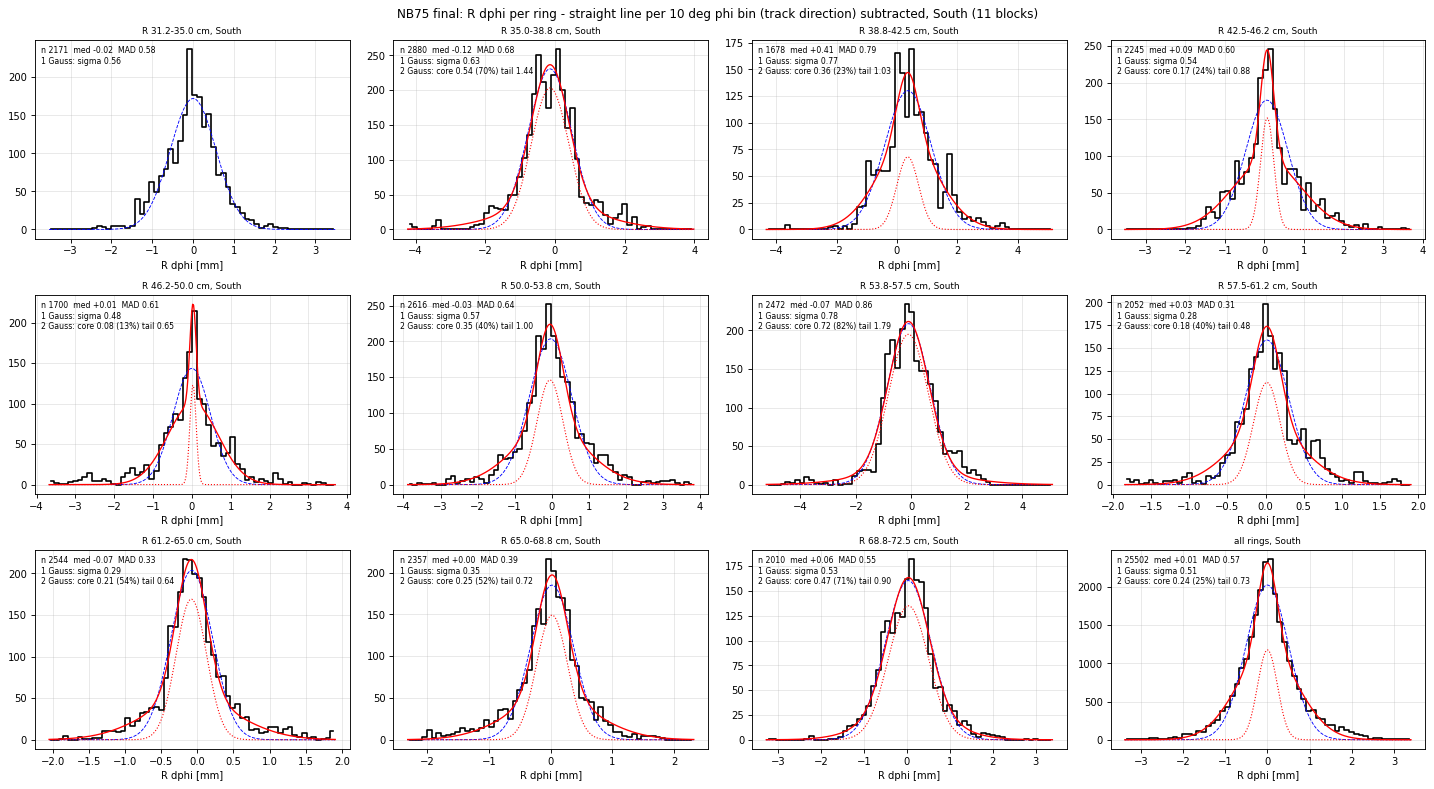

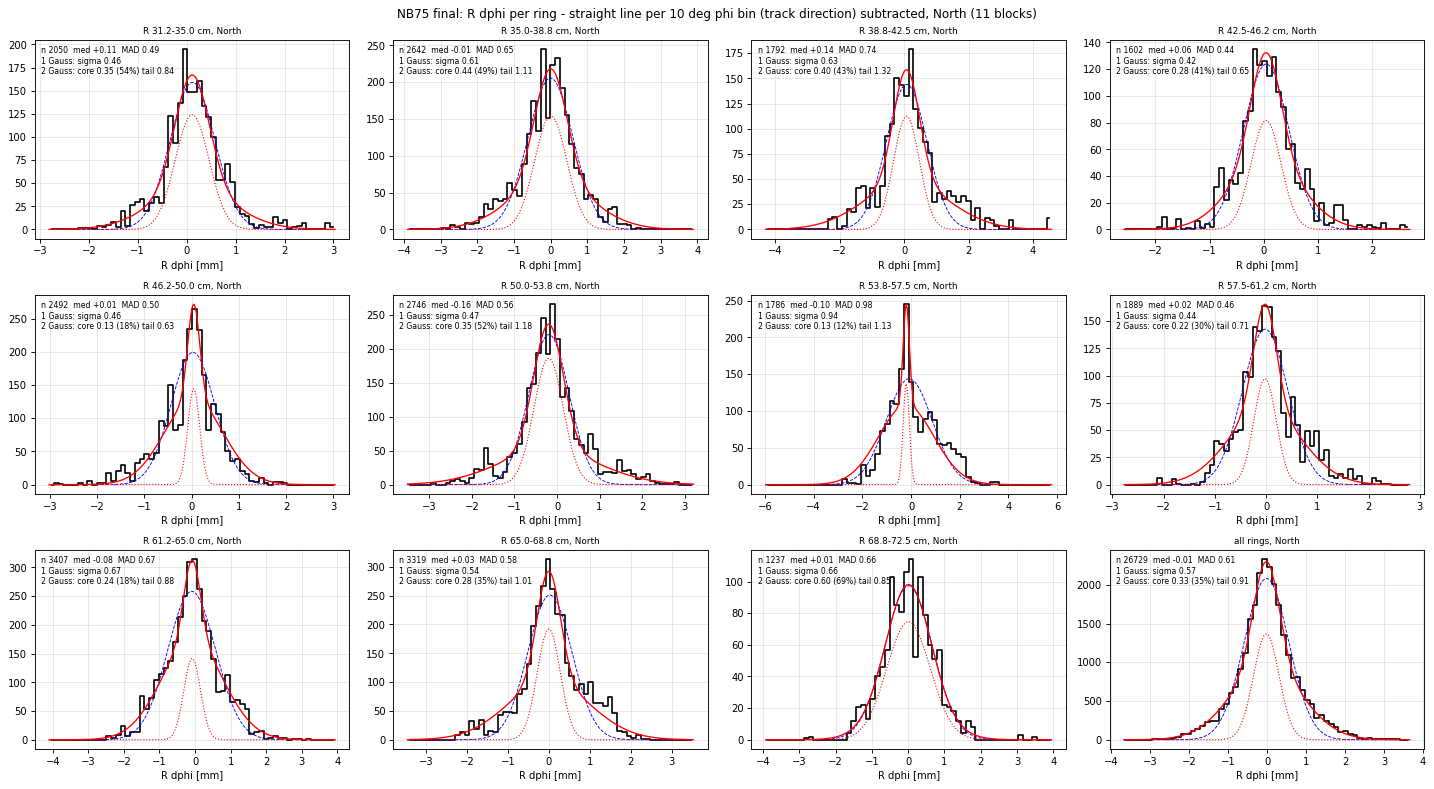

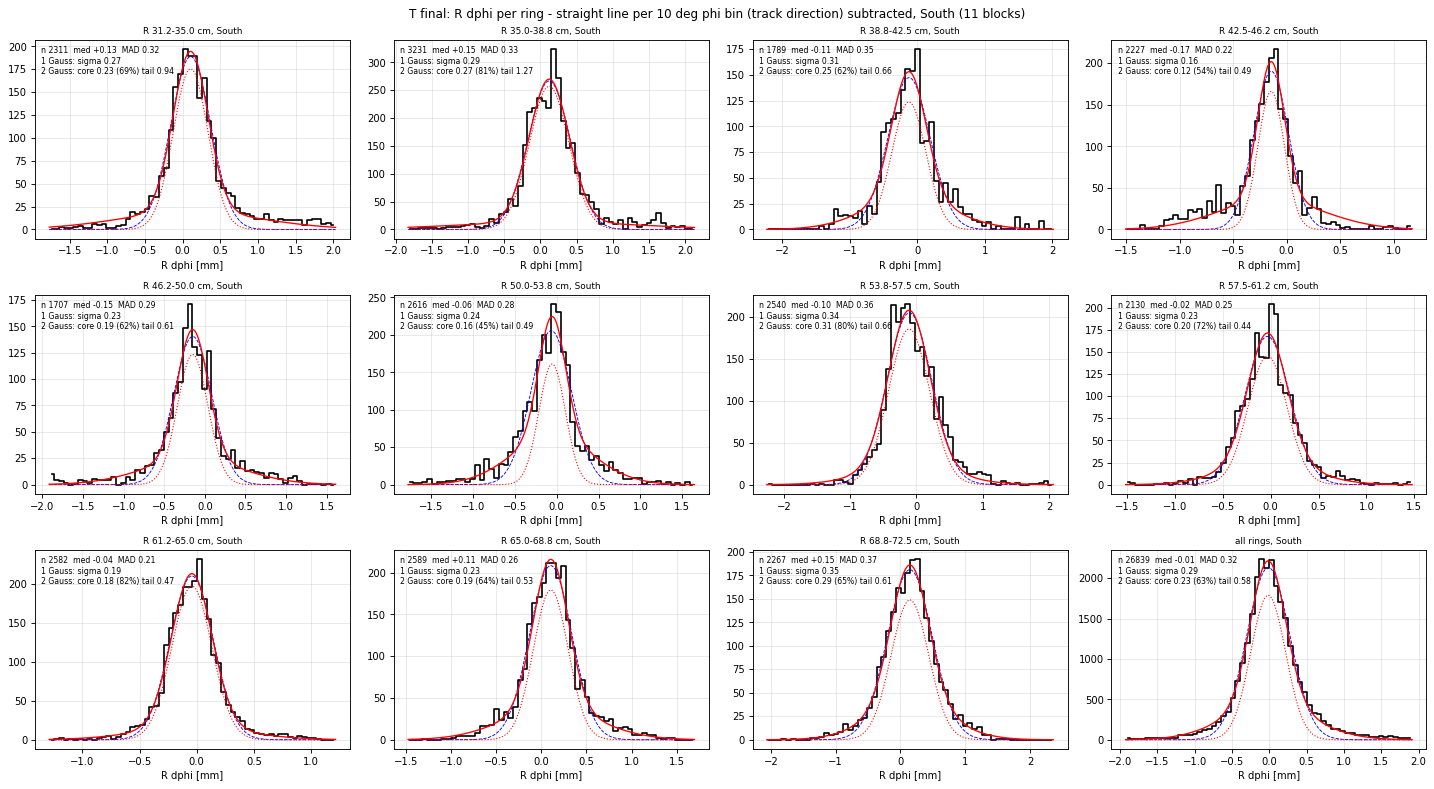

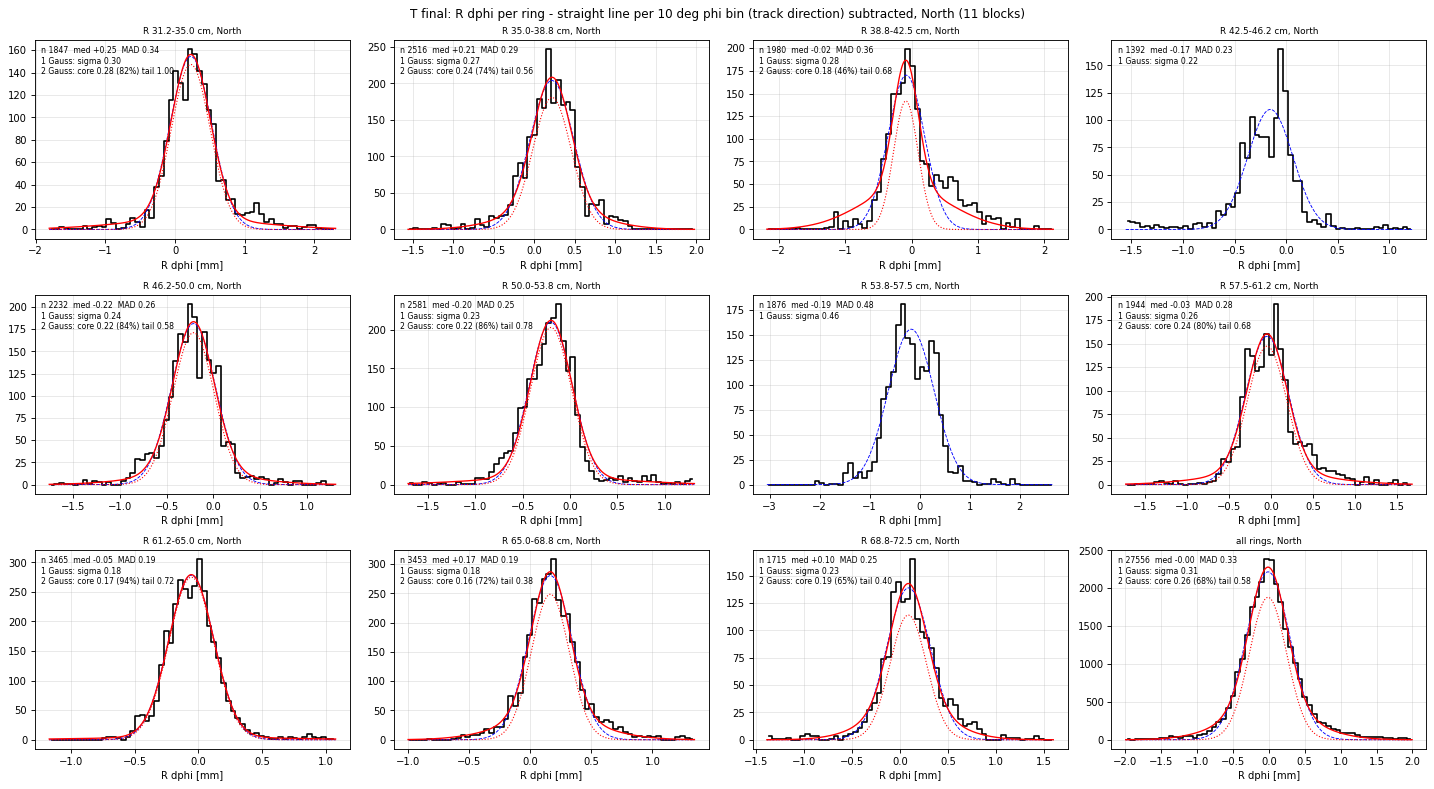

In [12]:
show(c.ring_hists('OFF', 'final', mode='line_phi'))     # beam - field off, straight line per track direction subtracted
show(c.ring_hists('NB75', 'final', mode='line_phi'))    # beam - no beam
show(c.ring_hists('T', 'final', mode='line_phi'))       # beam vs truth

## h) Run-by-run stability of the biases (final configuration, all 17 blocks)

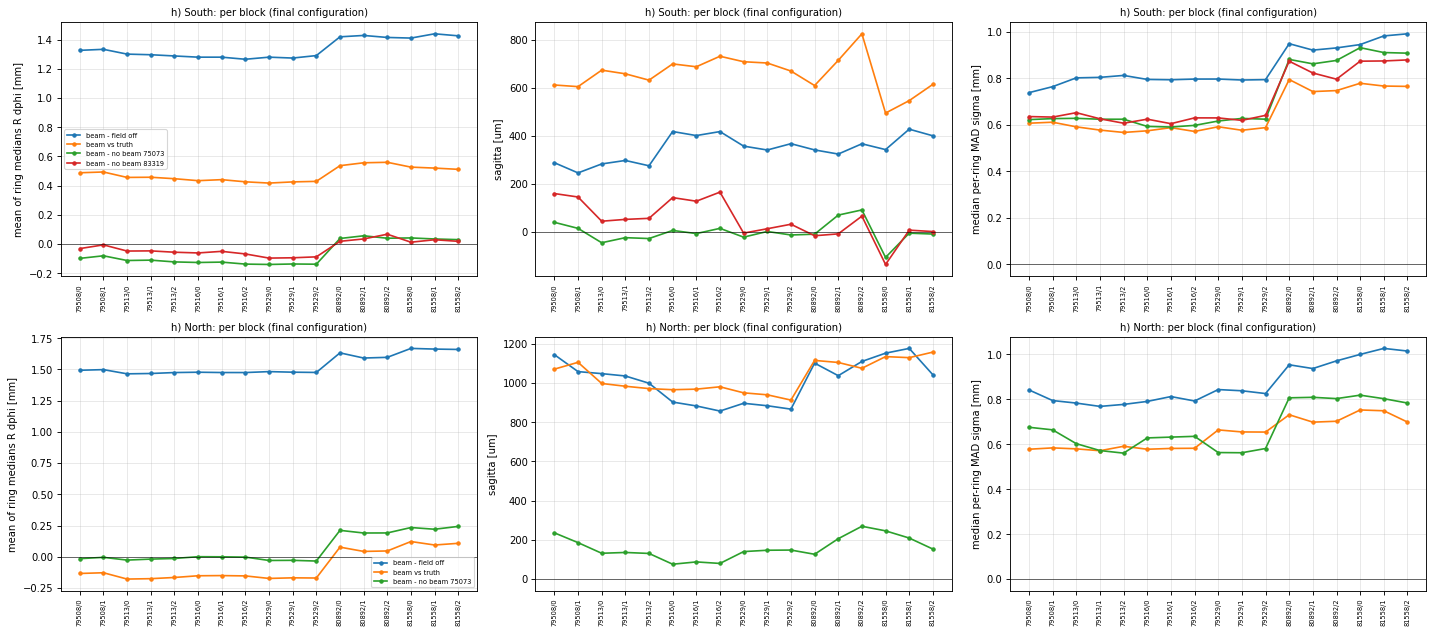

In [13]:
mh, eh = c.sec_h(); show(mh); pdfs['h'] = c.save_pdf('h_stability', mh + eh)

## k) keff vs GEM current, and all parameters
keff per block vs the GEM current at the block (TPC_CONDITIONS, SR1 / NR1 medians); within a run the segment-by-segment
GEM scaling holds to ~1 %.

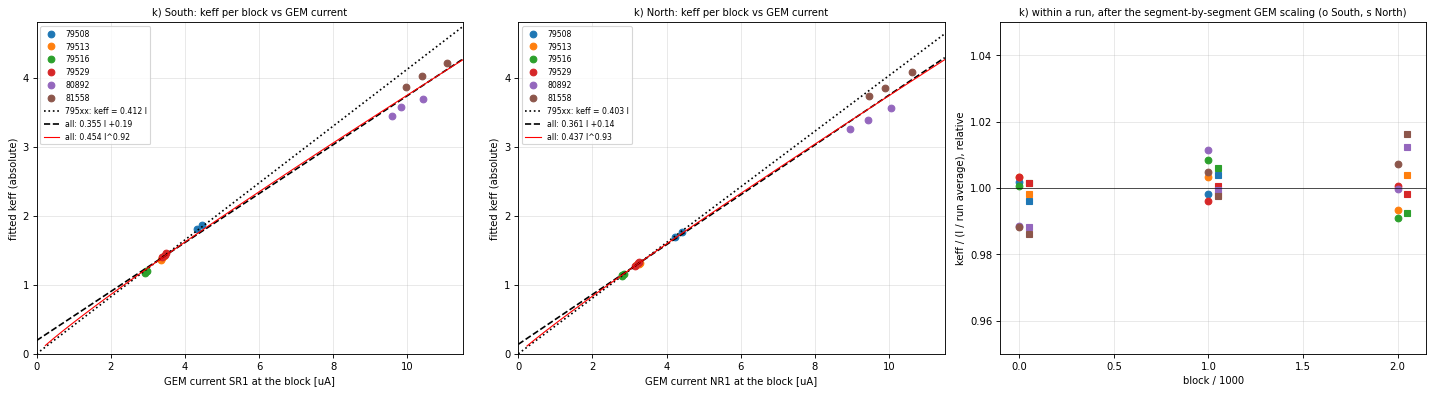

South: 795xx keff = 0.412 I;  all: 0.355 I +0.192;  power 0.454 I^0.92
North: 795xx keff = 0.403 I;  all: 0.361 I +0.137;  power 0.437 I^0.93


In [14]:
mk, ek, rows, fits = c.sec_k(K); show(mk); pdfs['k'] = c.save_pdf('k_keff_vs_gem', mk + ek)
for s in (0, 1):
    f = fits[s]
    print(f"{c.SIDES[s]}: 795xx keff = {f['prop795']:.3f} I;  all: {f['lin'][0]:.3f} I {f['lin'][1]:+.3f};  power {f['power'][0]:.3f} I^{f['power'][1]:.2f}")

### Parameter summary
| parameter | value | from |
|---|---|---|
| TPC tilt rot_x | +0.15 +- 0.05 mrad (used 0.16) | b: four first-harmonic measurements, all runs |
| TPC tilt rot_y | 0.86 +- 0.05 mrad (used 0.85) | b |
| TPC z shift | -30 +- 12 mm | c: North sagitta and N-S balance (field on - off, beam - off) |
| IFC South | +211 V after the change, 0 V before | d: 83319 - 75073 and the IFC scan |
| IFC North | 0 V | d |
| module-frame charge, CM field | no measurable effect; -180, 380 V/cm | d |
| SC map | alpha 1.6 (2.0 worse) | a |
| keff | 0.41 x I(SR1) South, 0.40 x I(NR1) North for 795xx; ~0.36-0.39 x I at 10 uA; segment-by-segment GEM scaling | e, k |

Open: constant +1.4 mm R dphi and -4..-5 mm dR between field on and field off (not in the drift model);
a U-shaped field-on R dphi residual (R1 and R3 high, sagitta +0.3..+1 mm vs field off / truth);
the North change between the beam runs and 83319; 80892 keff 12 % below the GEM line.

In [15]:
print("backup pdfs:"); [print(" ", v) for v in pdfs.values()]

backup pdfs:
  /home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/pdf/a_space_charge_beam_vs_nobeam.pdf
  /home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/pdf/b_tilt.pdf
  /home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/pdf/c_z_shift.pdf
  /home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/pdf/d_ifc_static_model.pdf
  /home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/pdf/e_keff.pdf
  /home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/pdf/f_residual_biases.pdf
  /home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/pdf/g_resolution.pdf
  /home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/pdf/h_stability.pdf
  /home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/pdf/k_keff_vs_gem.pdf


[None, None, None, None, None, None, None, None, None]